# Machine Learning Assignment 2
## M.Tech Artificial Intelligence and Machine Learning — BITS Pilani WILP

### Objective
The objective of this assignment is to implement and evaluate five Machine Learning classification algorithms using a publicly available Kaggle dataset. The performance of each model will be evaluated using appropriate classification metrics.

### Classification Models
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor (KNN) Classifier
4. Naive Bayes Classifier
5. Support Vector Machine (SVM)

### Evaluation Metrics
- Accuracy
- AUC Score
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

### Project Workflow
1. Dataset selection and exploration
2. Data preprocessing
3. Model implementation and training
4. Model evaluation and comparison
5. Performance observations and identification of the best model
6. Streamlit application development
7. Model deployment using Streamlit Community Cloud

### Dataset Source
Kaggle 

## 1. Dataset Loading and Initial Inspection

In this section, the Dry Bean Classification dataset downloaded from Kaggle is loaded into the Jupyter Notebook using the Pandas library. The dataset is inspected to understand its structure, dimensions, feature names, data types, and target variable before proceeding with data preprocessing and model implementation.

In [4]:

# Import required libraries
import pandas as pd
import numpy as np

# Load the Dry Bean dataset
df = pd.read_csv("Dry Beans Dataset.csv")

# Display the first five rows
print("First Five Rows of the Dataset:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())


First Five Rows of the Dataset:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Dataset Shape:
(13611, 17)

Column Names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRation', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733


## 2. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the dataset before model training. This section examines the distribution of target classes, checks for missing values and duplicate records, and visualizes the number of instances belonging to each bean class. These observations help understand the dataset and identify potential preprocessing requirements.

Missing Values in Each Column:
Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

Number of Duplicate Records:
68

Class Distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


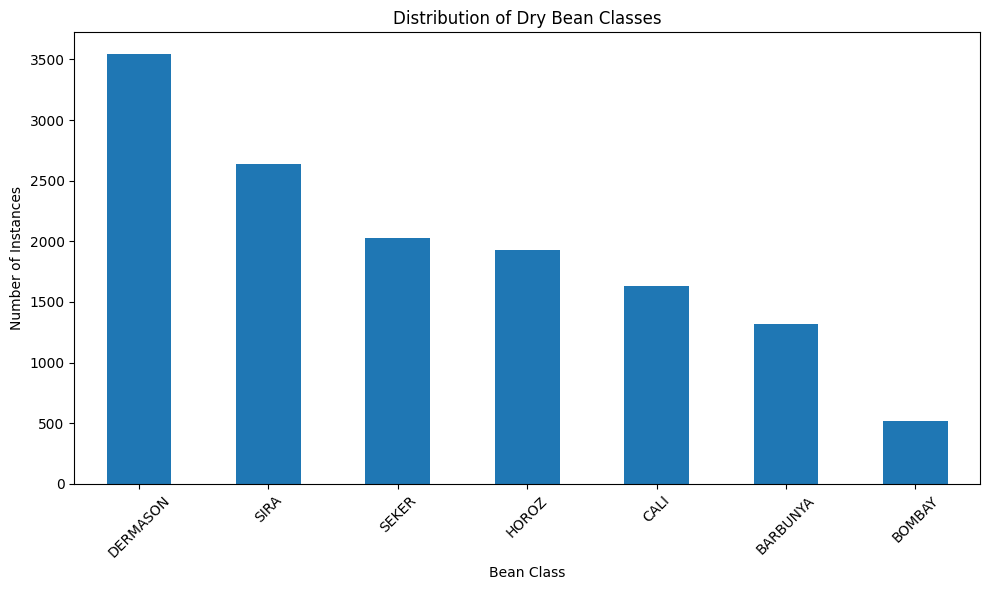

In [7]:

# Check for missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

# Check for duplicate records
print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

# Display the distribution of target classes
print("\nClass Distribution:")
print(df["Class"].value_counts())

# Visualize the class distribution
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
df["Class"].value_counts().plot(kind="bar")

plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Class")
plt.ylabel("Number of Instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 3. Data Cleaning and Preprocessing

The dataset contains 68 duplicate records and no missing values. Duplicate records are removed to reduce redundancy in the dataset. The updated dataset shape and class distribution are examined after removing duplicates.

In [10]:

# Remove duplicate records
df = df.drop_duplicates()

# Display updated dataset shape
print("Dataset Shape After Removing Duplicates:")
print(df.shape)

# Verify duplicate records
print("\nRemaining Duplicate Records:")
print(df.duplicated().sum())

# Display updated class distribution
print("\nUpdated Class Distribution:")
print(df["Class"].value_counts())


Dataset Shape After Removing Duplicates:
(13543, 17)

Remaining Duplicate Records:
0

Updated Class Distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1860
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


## 4. Feature Selection and Train-Test Split

The target variable is the `Class` column, which represents the category of dry bean. The remaining 16 numerical columns are used as input features.

The dataset is divided into 80% training data and 20% testing data. Stratified sampling is applied to preserve the class distribution in both subsets. A fixed random state is used to ensure reproducibility.

In [18]:

%pip install scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 94.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 160.9 MB/s eta 0:00:0000:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 128.6 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
Note: you may need to restart the kernel to use updated packages.


In [13]:

# Import required library
from sklearn.model_selection import train_test_split

# Separate input features and target variable
X = df.drop("Class", axis=1)
y = df["Class"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

# Display class distribution in training data
print("\nTraining Data Class Distribution:")
print(y_train.value_counts())

# Display class distribution in testing data
print("\nTesting Data Class Distribution:")
print(y_test.value_counts())


Training Data Shape: (10834, 16)
Testing Data Shape: (2709, 16)

Training Data Class Distribution:
Class
DERMASON    2837
SIRA        2109
SEKER       1621
HOROZ       1488
CALI        1304
BARBUNYA    1057
BOMBAY       418
Name: count, dtype: int64

Testing Data Class Distribution:
Class
DERMASON    709
SIRA        527
SEKER       406
HOROZ       372
CALI        326
BARBUNYA    265
BOMBAY      104
Name: count, dtype: int64


## 5. Feature Scaling

Feature scaling is performed to bring the numerical input features to a comparable scale. StandardScaler is used to transform the features by removing the mean and scaling them to unit variance.

Feature scaling is particularly important for Logistic Regression, K-Nearest Neighbor, and Support Vector Machine algorithms because these models are sensitive to the magnitude of the input features.

The scaler is fitted only on the training data to prevent data leakage. The same transformation is then applied to the testing data. Decision Tree and Gaussian Naive Bayes models will use the original numerical features.

In [15]:

# Import StandardScaler
from sklearn.preprocessing import StandardScaler

# Create the scaler
scaler = StandardScaler()

# Fit the scaler on training data and transform training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform testing data using the same scaler
X_test_scaled = scaler.transform(X_test)

# Display the shapes of scaled datasets
print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)

# Display the first five rows of scaled training data
print("\nFirst Five Rows of Scaled Training Data:")
display(pd.DataFrame(
    X_train_scaled,
    columns=X.columns
).head())


Scaled Training Data Shape: (10834, 16)
Scaled Testing Data Shape: (2709, 16)

First Five Rows of Scaled Training Data:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,0.560509,1.002462,0.925291,0.503525,0.786671,0.823696,0.582245,0.749885,-0.871715,-2.122169,-1.873432,-0.898136,-0.724272,-1.052294,-0.903132,-2.305622
1,1.017202,1.435815,0.840324,1.520932,-0.547166,-0.300388,1.021247,1.212690,1.562425,-0.541524,-1.746374,0.466374,-1.625335,-0.574239,0.435162,-0.156327
2,0.409630,0.787368,1.159812,-0.074614,2.145667,1.414271,0.403061,0.587300,0.688437,0.452249,-1.582650,-1.853622,-0.103932,-1.404477,-1.755383,-0.495135
3,-0.398662,-0.446283,-0.377380,-0.419042,-0.057031,0.213544,-0.403740,-0.398319,0.863458,0.754599,0.465657,-0.040240,0.349745,0.032920,-0.078360,0.583062
4,1.296921,1.464089,1.627602,1.146080,0.928970,0.903357,1.277206,1.477773,0.804356,1.093852,-0.604207,-0.959023,-1.346560,-1.308562,-0.959527,-0.171608


## 6. Model Implementation and Evaluation

### 6.1 Logistic Regression

Logistic Regression is a supervised Machine Learning classification algorithm that estimates the probability of an instance belonging to a particular class. It is extended to multiclass classification using the multinomial approach. In this assignment, Logistic Regression is trained on the standardized Dry Bean dataset to classify the seven bean varieties.

The model is evaluated using Accuracy, AUC Score, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

In [19]:

# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_scaled, y_train)

# Predict classes on testing data
y_pred_logistic = logistic_model.predict(X_test_scaled)

# Predict class probabilities for AUC calculation
y_prob_logistic = logistic_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

auc_logistic = roc_auc_score(
    y_test,
    y_prob_logistic,
    multi_class="ovr",
    average="weighted"
)

precision_logistic = precision_score(
    y_test, y_pred_logistic, average="weighted"
)

recall_logistic = recall_score(
    y_test, y_pred_logistic, average="weighted"
)

f1_logistic = f1_score(
    y_test, y_pred_logistic, average="weighted"
)

mcc_logistic = matthews_corrcoef(
    y_test, y_pred_logistic
)

# Display evaluation results
print("Logistic Regression Evaluation Results")
print("------------------------------------")
print("Accuracy:", round(accuracy_logistic, 4))
print("AUC Score:", round(auc_logistic, 4))
print("Precision:", round(precision_logistic, 4))
print("Recall:", round(recall_logistic, 4))
print("F1 Score:", round(f1_logistic, 4))
print("MCC Score:", round(mcc_logistic, 4))

# Display confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_logistic))

# Display classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_logistic))


Logistic Regression Evaluation Results
------------------------------------
Accuracy: 0.9199
AUC Score: 0.9935
Precision: 0.9205
Recall: 0.9199
F1 Score: 0.92
MCC Score: 0.9032

Confusion Matrix:
[[237   0  17   0   0   4   7]
 [  0 103   1   0   0   0   0]
 [  8   0 308   0   5   2   3]
 [  0   0   0 643   0  13  53]
 [  1   0  11   5 351   0   4]
 [  9   0   0   5   0 383   9]
 [  1   0   1  42   7   9 467]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.89      0.91       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.91      0.94      0.93       326
    DERMASON       0.93      0.91      0.92       709
       HOROZ       0.97      0.94      0.96       372
       SEKER       0.93      0.94      0.94       406
        SIRA       0.86      0.89      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0

### 6.2 Decision Tree Classifier

The Decision Tree Classifier is a supervised machine learning algorithm that uses a tree-like structure of decision rules to classify data. It divides the dataset based on feature values and predicts the class by following the decision path. In this experiment, the Decision Tree model is trained using the original unscaled training features and evaluated on the same test dataset using Accuracy, AUC, Precision, Recall, F1 Score, and MCC.

In [21]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Train the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

# Make predictions
y_pred_dt = dt_model.predict(X_test)
y_proba_dt = dt_model.predict_proba(X_test)

# Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_auc = roc_auc_score(
    y_test, y_proba_dt,
    multi_class="ovr", average="weighted"
)
dt_precision = precision_score(y_test, y_pred_dt, average="weighted")
dt_recall = recall_score(y_test, y_pred_dt, average="weighted")
dt_f1 = f1_score(y_test, y_pred_dt, average="weighted")
dt_mcc = matthews_corrcoef(y_test, y_pred_dt)

# Display results
print("Decision Tree Evaluation Results")
print("------------------------------------")
print(f"Accuracy: {dt_accuracy:.4f}")
print(f"AUC Score: {dt_auc:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall: {dt_recall:.4f}")
print(f"F1 Score: {dt_f1:.4f}")
print(f"MCC Score: {dt_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))


Decision Tree Evaluation Results
------------------------------------
Accuracy: 0.8955
AUC Score: 0.9357
Precision: 0.8954
Recall: 0.8955
F1 Score: 0.8953
MCC Score: 0.8737

Confusion Matrix:
[[237   0  18   1   0   4   5]
 [  0 104   0   0   0   0   0]
 [ 18   0 297   0   6   2   3]
 [  0   0   0 639   2  11  57]
 [  5   0  12   5 343   0   7]
 [  4   0   1  13   0 380   8]
 [  5   0   4  61   9  22 426]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.88      0.89      0.89       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.89      0.91      0.90       326
    DERMASON       0.89      0.90      0.89       709
       HOROZ       0.95      0.92      0.94       372
       SEKER       0.91      0.94      0.92       406
        SIRA       0.84      0.81      0.82       527

    accuracy                           0.90      2709
   macro avg       0.91      0.91      0.91      2709
weighted avg       0.90 

### 6.3 K-Nearest Neighbors (KNN)

K-Nearest Neighbors is a supervised machine learning algorithm that classifies a data point based on the classes of its nearest neighboring data points. It uses distance calculations to identify the nearest neighbors. In this experiment, KNN is trained using the scaled training features because feature scaling is important for distance-based algorithms. The model is evaluated on the same test dataset using Accuracy, AUC, Precision, Recall, F1 Score, and MCC.

In [24]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Train the KNN model
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_knn = knn_model.predict(X_test_scaled)
y_proba_knn = knn_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_auc = roc_auc_score(
    y_test, y_proba_knn,
    multi_class="ovr", average="weighted"
)
knn_precision = precision_score(y_test, y_pred_knn, average="weighted")
knn_recall = recall_score(y_test, y_pred_knn, average="weighted")
knn_f1 = f1_score(y_test, y_pred_knn, average="weighted")
knn_mcc = matthews_corrcoef(y_test, y_pred_knn)

# Display results
print("KNN Evaluation Results")
print("------------------------------------")
print(f"Accuracy: {knn_accuracy:.4f}")
print(f"AUC Score: {knn_auc:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall: {knn_recall:.4f}")
print(f"F1 Score: {knn_f1:.4f}")
print(f"MCC Score: {knn_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_knn))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_knn))


KNN Evaluation Results
------------------------------------
Accuracy: 0.9155
AUC Score: 0.9811
Precision: 0.9163
Recall: 0.9155
F1 Score: 0.9157
MCC Score: 0.8978

Confusion Matrix:
[[232   0  21   0   1   3   8]
 [  0 104   0   0   0   0   0]
 [  8   0 309   0   5   2   2]
 [  0   0   0 647   0  10  52]
 [  0   0  13   4 347   0   8]
 [  6   0   1   7   0 380  12]
 [  3   0   0  49   8   6 461]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.88      0.90       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.90      0.95      0.92       326
    DERMASON       0.92      0.91      0.91       709
       HOROZ       0.96      0.93      0.95       372
       SEKER       0.95      0.94      0.94       406
        SIRA       0.85      0.87      0.86       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92 

### 6.4 Gaussian Naive Bayes

Gaussian Naive Bayes is a probabilistic classification algorithm based on Bayes' theorem. It assumes that the features are conditionally independent given the class and that continuous features follow a Gaussian distribution. In this experiment, the model is trained using the original training features and evaluated on the test dataset using Accuracy, AUC, Precision, Recall, F1 Score, and MCC.

In [28]:

from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Train the Gaussian Naive Bayes model
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)

# Make predictions
y_pred_nb = nb_model.predict(X_test)
y_proba_nb = nb_model.predict_proba(X_test)

# Calculate evaluation metrics
nb_accuracy = accuracy_score(y_test, y_pred_nb)
nb_auc = roc_auc_score(
    y_test, y_proba_nb,
    multi_class="ovr", average="weighted"
)
nb_precision = precision_score(y_test, y_pred_nb, average="weighted")
nb_recall = recall_score(y_test, y_pred_nb, average="weighted")
nb_f1 = f1_score(y_test, y_pred_nb, average="weighted")
nb_mcc = matthews_corrcoef(y_test, y_pred_nb)

# Display results
print("Gaussian Naive Bayes Evaluation Results")
print("------------------------------------")
print(f"Accuracy: {nb_accuracy:.4f}")
print(f"AUC Score: {nb_auc:.4f}")
print(f"Precision: {nb_precision:.4f}")
print(f"Recall: {nb_recall:.4f}")
print(f"F1 Score: {nb_f1:.4f}")
print(f"MCC Score: {nb_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))


Gaussian Naive Bayes Evaluation Results
------------------------------------
Accuracy: 0.7630
AUC Score: 0.9644
Precision: 0.7647
Recall: 0.7630
F1 Score: 0.7607
MCC Score: 0.7143

Confusion Matrix:
[[122   0 108   0  24   0  11]
 [  0 104   0   0   0   0   0]
 [ 42   0 271   0  12   0   1]
 [  0   0   0 584   0  85  40]
 [ 14   0  15   8 295   0  40]
 [  2   0   0  56   6 283  59]
 [  0   0   0  23  41  55 408]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.68      0.46      0.55       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.69      0.83      0.75       326
    DERMASON       0.87      0.82      0.85       709
       HOROZ       0.78      0.79      0.79       372
       SEKER       0.67      0.70      0.68       406
        SIRA       0.73      0.77      0.75       527

    accuracy                           0.76      2709
   macro avg       0.77      0.77      0.77      2709
weighted avg     

### 6.5 Support Vector Machine (SVM)

Support Vector Machine is a supervised machine learning algorithm that identifies an optimal decision boundary to separate classes. It uses support vectors, which are the data points closest to the decision boundary. In this experiment, the SVM model uses a Radial Basis Function (RBF) kernel and scaled features. The model is evaluated using Accuracy, AUC, Precision, Recall, F1 Score, and MCC.

In [31]:

from sklearn.svm import SVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

# Train the calibrated SVM model
svm_model = CalibratedClassifierCV(
    SVC(kernel="rbf", random_state=42),
    ensemble=False
)
svm_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_svm = svm_model.predict(X_test_scaled)
y_proba_svm = svm_model.predict_proba(X_test_scaled)

# Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_auc = roc_auc_score(
    y_test, y_proba_svm,
    multi_class="ovr", average="weighted"
)
svm_precision = precision_score(y_test, y_pred_svm, average="weighted")
svm_recall = recall_score(y_test, y_pred_svm, average="weighted")
svm_f1 = f1_score(y_test, y_pred_svm, average="weighted")
svm_mcc = matthews_corrcoef(y_test, y_pred_svm)

# Display results
print("SVM Evaluation Results")
print("------------------------------------")
print(f"Accuracy: {svm_accuracy:.4f}")
print(f"AUC Score: {svm_auc:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall: {svm_recall:.4f}")
print(f"F1 Score: {svm_f1:.4f}")
print(f"MCC Score: {svm_mcc:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_svm))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_svm))


SVM Evaluation Results
------------------------------------
Accuracy: 0.9210
AUC Score: 0.9885
Precision: 0.9214
Recall: 0.9210
F1 Score: 0.9211
MCC Score: 0.9045

Confusion Matrix:
[[236   0  18   0   1   4   6]
 [  0 104   0   0   0   0   0]
 [  7   0 309   0   6   2   2]
 [  0   0   0 647   0  13  49]
 [  1   0   7   5 351   0   8]
 [  4   0   0   6   0 386  10]
 [  3   0   0  47   7   8 462]]

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.94      0.89      0.91       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.95      0.94       326
    DERMASON       0.92      0.91      0.92       709
       HOROZ       0.96      0.94      0.95       372
       SEKER       0.93      0.95      0.94       406
        SIRA       0.86      0.88      0.87       527

    accuracy                           0.92      2709
   macro avg       0.93      0.93      0.93      2709
weighted avg       0.92      0.92 

## 7. Comparative Analysis of Models

The performance of the five classification models is compared using Accuracy, AUC, Precision, Recall, F1 Score, and Matthews Correlation Coefficient (MCC). All models were evaluated on the same test dataset to ensure a fair comparison. The comparison helps identify the most suitable model for classifying Dry Beans.

In [33]:

from sklearn.linear_model import LogisticRegression

# Train Logistic Regression model
lr_model = LogisticRegression(max_iter=2000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


In [34]:

from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef
)
import pandas as pd

# Function to calculate evaluation metrics
def calculate_metrics(model, X_test_data, y_test):
    predictions = model.predict(X_test_data)
    probabilities = model.predict_proba(X_test_data)

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "AUC": roc_auc_score(
            y_test, probabilities,
            multi_class="ovr", average="weighted"
        ),
        "Precision": precision_score(
            y_test, predictions, average="weighted"
        ),
        "Recall": recall_score(
            y_test, predictions, average="weighted"
        ),
        "F1 Score": f1_score(
            y_test, predictions, average="weighted"
        ),
        "MCC": matthews_corrcoef(y_test, predictions)
    }

# Calculate metrics for each trained model
results = {
    "Logistic Regression": calculate_metrics(
        lr_model, X_test_scaled, y_test
    ),
    "Decision Tree": calculate_metrics(
        dt_model, X_test, y_test
    ),
    "KNN": calculate_metrics(
        knn_model, X_test_scaled, y_test
    ),
    "Gaussian Naive Bayes": calculate_metrics(
        nb_model, X_test, y_test
    ),
    "SVM": calculate_metrics(
        svm_model, X_test_scaled, y_test
    )
}

# Create and display the comparison table
comparison_df = pd.DataFrame(results).T
comparison_df.round(4)


,Accuracy,AUC,Precision,Recall,F1 Score,MCC
Logistic Regression,0.9199,0.9935,0.9205,0.9199,0.9200,0.9032
Decision Tree,0.8955,0.9357,0.8954,0.8955,0.8953,0.8737
KNN,0.9155,0.9811,0.9163,0.9155,0.9157,0.8978
Gaussian Naive Bayes,0.7630,0.9644,0.7647,0.7630,0.7607,0.7143
SVM,0.9210,0.9885,0.9214,0.9210,0.9211,0.9045


## Model Performance Observations

| ML Model | Observation about Model Performance |
|---|---|
| Logistic Regression | Achieved an accuracy of 91.99% and the highest AUC score of 0.9935, indicating excellent classification performance and class discrimination. |
| Decision Tree | Achieved an accuracy of 89.55%. Its performance was lower than the other models, indicating comparatively weaker generalization on the test dataset. |
| KNN | Achieved an accuracy of 91.55% and an AUC of 0.9811, demonstrating good classification performance. |
| Gaussian Naive Bayes | Achieved the lowest accuracy of 76.30%, although its AUC score of 0.9644 indicates good class discrimination. |
| Support Vector Machine (SVM) | Achieved the highest accuracy, precision, recall, F1 score, and MCC, making it the best overall-performing model based on these metrics. |

**Overall Winner:** Support Vector Machine (SVM), with an accuracy of 92.10% and an MCC score of 0.9045. Logistic Regression achieved the highest AUC score of 0.9935.

## Saving Trained Models

In this section, we identify the trained classification models and prepare them for saving. The existing trained models will be reused for deployment.

In [37]:
from sklearn.base import BaseEstimator

for name, obj in globals().copy().items():
    if isinstance(obj, BaseEstimator):
        print(name, ":", type(obj).__name__)

scaler : StandardScaler
logistic_model : LogisticRegression
dt_model : DecisionTreeClassifier
knn_model : KNeighborsClassifier
nb_model : GaussianNB
svm_model : CalibratedClassifierCV
lr_model : LogisticRegression


## Verify Trained Model Objects

Check the fitted status of the existing Logistic Regression objects before saving the trained models.

In [39]:
from sklearn.utils.validation import check_is_fitted

for name in ["logistic_model", "lr_model"]:
    model = globals()[name]
    try:
        check_is_fitted(model)
        print(f"{name}: Fitted")
    except Exception:
        print(f"{name}: Not fitted")

logistic_model: Fitted
lr_model: Fitted


## Save Trained Models and Test Data

The five trained classification models and the StandardScaler preprocessing object are saved using Joblib. The test dataset is also exported as a CSV file for use in the Streamlit application. The models are saved without retraining.

In [41]:
import os
import joblib
import pandas as pd

# Create folders
os.makedirs("model", exist_ok=True)

# Existing trained models
models = {
    "logistic_regression": logistic_model,
    "decision_tree": dt_model,
    "knn": knn_model,
    "naive_bayes": nb_model,
    "svm": svm_model
}

# Save all trained models
for name, model in models.items():
    joblib.dump(model, f"model/{name}.joblib")
    print(f"Saved: {name}.joblib")

# Save the fitted scaler
joblib.dump(scaler, "model/scaler.joblib")
print("Saved: scaler.joblib")

# Export test data with original feature values and target column
test_data = pd.concat([X_test, y_test], axis=1)
test_data.to_csv("test_data.csv", index=False)

print("Saved: test_data.csv")
print("Test data shape:", test_data.shape)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: naive_bayes.joblib
Saved: svm.joblib
Saved: scaler.joblib
Saved: test_data.csv
Test data shape: (2709, 17)


## Streamlit Application Development

This section creates an interactive Streamlit application that loads the saved classification models and preprocessing scaler. Users can upload test data, select a model, and view its evaluation metrics, confusion matrix, and classification report.

In [44]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Page configuration
st.set_page_config(
    page_title="Dry Bean Classification",
    page_icon="🌱",
    layout="wide"
)

st.title("🌱 Dry Bean Classification")
st.write(
    "Upload your test dataset and select a trained machine learning model "
    "to evaluate its classification performance."
)

# Load saved models and scaler
@st.cache_resource
def load_models():
    models = {
        "Logistic Regression": joblib.load("model/logistic_regression.joblib"),
        "Decision Tree": joblib.load("model/decision_tree.joblib"),
        "K-Nearest Neighbors": joblib.load("model/knn.joblib"),
        "Gaussian Naive Bayes": joblib.load("model/naive_bayes.joblib"),
        "Support Vector Machine": joblib.load("model/svm.joblib")
    }

    scaler = joblib.load("model/scaler.joblib")

    return models, scaler

models, scaler = load_models()

# Dataset upload
uploaded_file = st.file_uploader(
    "Upload Test Dataset (CSV)",
    type=["csv"]
)

if uploaded_file is not None:

    data = pd.read_csv(uploaded_file)

    st.subheader("Uploaded Dataset")
    st.dataframe(data.head())

    target_column = "Class"

    if target_column not in data.columns:
        st.error("The uploaded dataset must contain the 'Class' target column.")

    else:
        X_test = data.drop(columns=[target_column])
        y_test = data[target_column]

        expected_features = list(scaler.feature_names_in_)

        if list(X_test.columns) != expected_features:
            st.error(
                "The uploaded dataset must contain the required input features "
                "in the same order as the training dataset."
            )

        else:
            # Apply the existing fitted scaler
            X_test_scaled = scaler.transform(X_test)

            # Model selection
            selected_model_name = st.selectbox(
                "Select Classification Model",
                list(models.keys())
            )

            selected_model = models[selected_model_name]

            # Predictions
            y_pred = selected_model.predict(X_test_scaled)
            y_prob = selected_model.predict_proba(X_test_scaled)

            # Evaluation metrics
            accuracy = accuracy_score(y_test, y_pred)

            auc = roc_auc_score(
                y_test,
                y_prob,
                multi_class="ovr",
                average="weighted"
            )

            precision = precision_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            recall = recall_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            f1 = f1_score(
                y_test, y_pred, average="weighted", zero_division=0
            )

            mcc = matthews_corrcoef(y_test, y_pred)

            # Display metrics
            st.subheader("Evaluation Metrics")

            col1, col2, col3 = st.columns(3)

            col1.metric("Accuracy", f"{accuracy:.4f}")
            col2.metric("AUC Score", f"{auc:.4f}")
            col3.metric("Precision", f"{precision:.4f}")

            col4, col5, col6 = st.columns(3)

            col4.metric("Recall", f"{recall:.4f}")
            col5.metric("F1 Score", f"{f1:.4f}")
            col6.metric("MCC Score", f"{mcc:.4f}")

            # Confusion matrix
            st.subheader("Confusion Matrix")

            labels = selected_model.classes_

            cm = confusion_matrix(
                y_test,
                y_pred,
                labels=labels
            )

            fig, ax = plt.subplots(figsize=(9, 7))

            display = ConfusionMatrixDisplay(
                confusion_matrix=cm,
                display_labels=labels
            )

            display.plot(
                ax=ax,
                cmap="Blues",
                xticks_rotation=45
            )

            st.pyplot(fig)
            plt.close(fig)

            # Classification report
            st.subheader("Classification Report")

            report = classification_report(
                y_test,
                y_pred,
                output_dict=True,
                zero_division=0
            )

            report_df = pd.DataFrame(report).transpose()

            st.dataframe(report_df)

else:
    st.info("Please upload the test_data.csv file to begin evaluation.")

Overwriting app.py


## Creating Requirements File

The requirements file specifies the Python libraries required to run the Streamlit application and load the saved machine learning models.

In [47]:
%%writefile requirements.txt

streamlit
pandas
numpy
scikit-learn
matplotlib
joblib

Overwriting requirements.txt


## Preparing the GitHub README

The README file documents the Dry Bean Classification project, dataset, machine learning models, evaluation metrics, and model performance observations. It will also be included in the final assignment PDF.

In [55]:
%%writefile README.md

# Dry Bean Classification using Machine Learning

## 1. Problem Statement

The objective of this project is to develop and evaluate machine learning classification models to identify different varieties of dry beans based on their morphological characteristics. Five classification algorithms are implemented and compared using multiple evaluation metrics.

## 2. Dataset Description

The Dry Beans Dataset contains numerical features describing the shape and characteristics of dry bean samples.

- Number of input features: 16
- Number of classes: 7
- Dataset instances after duplicate removal: 13,543
- Training samples: 10,834
- Testing samples: 2,709
- Target variable: Class

The dataset is used to train and evaluate five classification models.

## 3. GitHub Repository Link

Repository Link: To be added after creating the GitHub repository.

## 4. Models Used and Evaluation

The following classification models were implemented:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Support Vector Machine (SVM)

### Model Comparison Table

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 Score | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9199 | 0.9935 | 0.9205 | 0.9199 | 0.9200 | 0.9032 |
| Decision Tree | 0.8955 | 0.9357 | 0.8954 | 0.8955 | 0.8953 | 0.8737 |
| KNN | 0.9155 | 0.9811 | 0.9163 | 0.9155 | 0.9157 | 0.8978 |
| Gaussian Naive Bayes | 0.7630 | 0.9644 | 0.7647 | 0.7630 | 0.7607 | 0.7143 |
| SVM | 0.9210 | 0.9885 | 0.9214 | 0.9210 | 0.9211 | 0.9045 |

### Model Performance Observations

| ML Model Name | Observation |
|---|---|
| Logistic Regression | Achieved 91.99% accuracy and the highest AUC score of 0.9935, indicating excellent classification performance. |
| Decision Tree | Achieved 89.55% accuracy, which was lower than the other models in this experiment. |
| KNN | Achieved 91.55% accuracy and an AUC score of 0.9811, showing good classification performance. |
| Gaussian Naive Bayes | Achieved the lowest accuracy of 76.30%, although its AUC score was 0.9644. |
| Support Vector Machine | Achieved the highest accuracy, precision, recall, F1 score, and MCC among the evaluated models. |

### Overall Winner

The Support Vector Machine (SVM) was the overall winner based on accuracy, precision, recall, F1 score, and MCC. It achieved an accuracy of 92.10% and an MCC score of 0.9045. Logistic Regression achieved the highest AUC score of 0.9935.

## 5. Technologies Used

- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Streamlit
- Joblib

## 6. Application Features

- Upload test data in CSV format
- Select a machine learning classification model
- Display evaluation metrics
- Visualize the confusion matrix
- Display the classification report

## 7. Project Files

- `app.py` - Streamlit application
- `requirements.txt` - Required Python packages
- `README.md` - Project documentation
- `test_data.csv` - Test dataset
- `model/` - Saved trained models and scaler

Overwriting README.md


## Installing Dependencies and Testing the Application

Install the required Python packages and verify that the Streamlit application can be launched before deployment.

In [74]:
%pip install -r requirements.txt

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 107.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 797.2/797.2 kB 46.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.0/55.0 MB 140.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 106.2 MB/s eta 0:00:00
  Attempting uninstall: typing-extensions
    Found existing installation: typing_extensions 4.11.0
    Uninstalling typing_extensions-4.11.0:
      Successfully uninstalled typing_extensions-4.11.0
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.3
    Uninstalling protobuf-4.25.3:
      Successfully uninstalled protobuf-4.25.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.17.0 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<5.0.0dev,>=3.20.3, but you have protobuf 7.

In [2]:
print("Notebook is working")

Notebook is working


In [6]:
import subprocess

process = subprocess.Popen(
    ["streamlit", "run", "app.py", "--server.headless", "true"],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True
)

print("Streamlit process started:", process.pid)

Streamlit process started: 10008


In [8]:


print(process.poll())

None


In [10]:
print(process.stdout.readline())

In [12]:
import requests

try:
    response = requests.get("http://localhost:8501", timeout=10)
    print("Status:", response.status_code)
except Exception as e:
    print("Error:", e)

Status: 200


In [14]:
from IPython.display import IFrame, display

display(IFrame(src="http://localhost:8501", width=1000, height=700))

In [16]:
!ls -la

total 3296
drwxr-xr-x. 4 s2026aj05380 s2026aj05380    6144 Nov  8 19:19  .
drwxr-xr-x. 5 s2026aj05380 s2026aj05380    6144 Nov  8 17:12  ..
-rw-r--r--. 1 s2026aj05380 s2026aj05380  145660 Nov  8 19:19  2026AJ05380.ipynb
-rw-r--r--. 1 s2026aj05380 s2026aj05380    4680 Nov  8 19:01  app.py
-rw-r--r--. 1 s2026aj05380 s2026aj05380 2663219 Nov  8 18:01 'Dry Beans Dataset.csv'
drwxr-xr-x. 2 s2026aj05380 s2026aj05380    6144 Nov  8 17:13  .ipynb_checkpoints
drwxr-xr-x. 2 s2026aj05380 s2026aj05380    6144 Nov  8 18:48  model
-rw-r--r--. 1 s2026aj05380 s2026aj05380    3008 Nov  8 19:01  README.md
-rw-r--r--. 1 s2026aj05380 s2026aj05380      55 Nov  8 19:01  requirements.txt
-rw-r--r--. 1 s2026aj05380 s2026aj05380  527609 Nov  8 19:01  test_data.csv
